# 03. Eksploracja ścieżki: klasyfikator na punktach charakterystycznych

**Miejsce w procesie:** przed oficjalnym modelem baseline. Mamy dwa kandydujące potoki i chcemy mieć dowody,
zanim wybierzemy jeden:

| | Ścieżka A: punkty charakterystyczne | Ścieżka B: wycinek obrazu |
|---|---|---|
| Wejście do naszego modelu | 21 landmarków dłoni z MediaPipe (42 liczby) | wycinek dłoni, np. 128x128 px |
| Nasz model | mały klasyfikator (regresja logistyczna, drzewa, MLP) | mała sieć CNN (np. MobileNetV3) |
| Czy trening wymaga obrazów | nie, landmarki są w adnotacjach | tak |
| Detektor dłoni w aplikacji | MediaPipe (daje landmarki) | MediaPipe albo mały detektor (daje wycinek) |
| Zgodność z krokami kursu | przetwarzanie wstępne i augmentacja działają na punktach, Grad-CAM nie pasuje (SHAP tak) | wszystkie kroki pasują wprost |

Ten notebook testuje ścieżkę A, bo nie potrzebuje obrazów. Ścieżka B czeka na podzbiór obrazów.

**Zasady dla każdego uruchomienia w tym notebooku:**
- Oficjalne podziały rozłączne po osobach. Stroimy i porównujemy na **val**, test zostaje nietknięty aż do
  ostatecznego modelu.
- Główna metryka to **macro F1**, bo klasy docelowe są niezbalansowane 8:1 (zob. `02_eda.ipynb`).
- Każdy trening mierzymy CodeCarbonem (energia, CO2, czas) i dopisujemy do `experiments/log.csv`.

In [1]:
import sys
sys.path.insert(0, "../src")

import pickle
import time
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from sklearn.ensemble import HistGradientBoostingClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix, f1_score
from sklearn.neural_network import MLPClassifier
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler

from features import extended_fingers, landmarks, normalise
from greenai import log_experiment, track
from labels import GESTURE_TO_COUNT

FIG = Path("../reports/figures")
MODELS = Path("../models/explore")
MODELS.mkdir(parents=True, exist_ok=True)
sns.set_theme(style="whitegrid")
RNG = 0

## Dane

Tylko dłonie ze zmapowanym gestem i z landmarkami. Cechy to 21 punktów przesuniętych tak, żeby nadgarstek był
w (0, 0), i przeskalowanych tak, żeby dłoń mieściła się w kole jednostkowym. To usuwa położenie i wielkość dłoni
w kadrze.

In [2]:
hands = pd.read_parquet("../data/interim/hands.parquet")
hands = hands[hands.label.isin(list(GESTURE_TO_COUNT)) & hands.has_landmarks].reset_index(drop=True)
hands["y"] = hands.label.map(GESTURE_TO_COUNT).astype(int)

def xy(split):
    d = hands[hands.split == split]
    return normalise(landmarks(d)).reshape(len(d), -1), d.y.to_numpy(), d

X_tr, y_tr, d_tr = xy("train")
X_va, y_va, d_va = xy("val")
print(f"train {X_tr.shape}, val {X_va.shape}")

train (612590, 42), val (76669, 42)


## R0: punkt odniesienia oparty na regule (bez treningu)

Liczymy palce, które reguła kątów w stawach z `02_eda.ipynb` uznaje za wyprostowane. Nie ma tu uczenia, więc
zużycie energii jest praktycznie zerowe. Każdy trenowany model musi to pobić.

In [3]:
results = []

def evaluate(name, y_pred, extra):
    row = {"model": name, "val_accuracy": accuracy_score(y_va, y_pred), "val_macro_f1": f1_score(y_va, y_pred, average="macro"),
           **extra}
    results.append(row)
    return row

rule_pred = extended_fingers(landmarks(d_va)).n_extended.to_numpy()
row = evaluate("R0 reguła", rule_pred, {"train_time_s": 0, "energy_kwh": 0, "co2_g": 0})
log_experiment(experiment_id="explore-A-R0", path="A keypoints", process_step="path exploration",
               model="reguła kątów w stawach", train_samples=0, val_accuracy=round(row["val_accuracy"], 4),
               val_macro_f1=round(row["val_macro_f1"], 4), train_time_s=0, energy_kwh=0, co2_g=0, model_size_kb=0,
               notes="kąty w stawach 2D > 150 st., bez treningu")
pd.DataFrame([row])

,model,val_accuracy,val_macro_f1,train_time_s,energy_kwh,co2_g
0,R0 reguła,0.754855,0.674937,0,0,0


## Trenowani kandydaci

Trzy rodziny modeli z listy kursu: klasyfikator liniowy, model drzewiasty i mała sieć neuronowa.
Celowo prawie domyślne hiperparametry. Strojenie to późniejszy krok procesu.

In [4]:
candidates = {
    "M1 regresja logistyczna": make_pipeline(StandardScaler(), LogisticRegression(max_iter=2000, class_weight="balanced")),
    "M2 drzewa gradient boosting": HistGradientBoostingClassifier(max_iter=300, class_weight="balanced", random_state=RNG),
    "M3 MLP 128-64": make_pipeline(StandardScaler(), MLPClassifier(hidden_layer_sizes=(128, 64), early_stopping=True,
                                                                     max_iter=50, random_state=RNG)),
}

def latency_ms(model, n=2000):
    """Średni czas predykcji jednej próbki, przybliżony koszt na klatkę (z narzutem sklearn)."""
    x = X_va[:1]
    t0 = time.perf_counter()
    for _ in range(n):
        model.predict(x)
    return (time.perf_counter() - t0) / n * 1000

fitted = {}
for name, model in candidates.items():
    with track(name) as g:
        model.fit(X_tr, y_tr)
    pred = model.predict(X_va)
    size_kb = len(pickle.dumps(model)) / 1024
    lat = latency_ms(model)
    row = evaluate(name, pred, {**g, "model_size_kb": size_kb, "latency_ms": lat})
    fitted[name] = (model, pred)
    pickle.dump(model, open(MODELS / f"{name.split()[0]}.pkl", "wb"))
    log_experiment(experiment_id=f"explore-A-{name.split()[0]}", path="A keypoints", process_step="path exploration",
                   model=name.split(" ", 1)[1], train_samples=len(y_tr), val_accuracy=round(row["val_accuracy"], 4),
                   val_macro_f1=round(row["val_macro_f1"], 4), train_time_s=round(g["train_time_s"], 1),
                   energy_kwh=f"{g['energy_kwh']:.6f}", co2_g=round(g["co2_g"], 3), model_size_kb=round(size_kb, 1),
                   latency_ms=round(lat, 3),
                   notes="landmarki wycentrowane na nadgarstku, przeskalowane do koła jednostkowego, domyślne hiperparametry")
    print(f"{name}: macro F1 {row['val_macro_f1']:.3f}, {g['train_time_s']:.0f}s, {g['co2_g']:.2f} g CO2")

[codecarbon INFO @ 16:24:00] offline tracker init


[codecarbon WARNING @ 16:24:00] Multiple instances of codecarbon are allowed to run at the same time.


M1 regresja logistyczna: macro F1 0.854, 45s, 0.24 g CO2


M2 drzewa gradient boosting: macro F1 0.988, 26s, 0.32 g CO2


M3 MLP 128-64: macro F1 0.993, 27s, 0.17 g CO2


In [5]:
summary = pd.DataFrame(results).set_index("model")
summary.style.format({"val_accuracy": "{:.3f}", "val_macro_f1": "{:.3f}", "train_time_s": "{:.1f}", "energy_kwh": "{:.5f}",
                      "co2_g": "{:.2f}", "model_size_kb": "{:.0f}", "latency_ms": "{:.3f}"}, na_rep="-")

,val_accuracy,val_macro_f1,train_time_s,energy_kwh,co2_g,model_size_kb,latency_ms
model,,,,,,,
R0 reguła,0.755,0.675,0.0,0.00000,0.00,-,-
M1 regresja logistyczna,0.805,0.854,44.9,0.00036,0.24,3,0.119
M2 drzewa gradient boosting,0.989,0.988,26.4,0.00048,0.32,1144,14.463
M3 MLP 128-64,0.994,0.993,27.0,0.00026,0.17,175,0.146


## Skąd biorą się błędy?

In [6]:
best_name = summary.drop("R0 reguła").val_macro_f1.idxmax()
best_model, best_pred = fitted[best_name]
print(best_name)
print(classification_report(y_va, best_pred, digits=3))

M3 MLP 128-64
              precision    recall  f1-score   support

           0      0.983     0.991     0.987      2923
           1      0.990     0.995     0.992     20436
           2      0.995     0.992     0.993     26454
           3      0.997     0.995     0.996     14929
           4      0.990     0.993     0.992      2992
           5      0.997     0.997     0.997      8935

    accuracy                          0.994     76669
   macro avg      0.992     0.994     0.993     76669
weighted avg      0.994     0.994     0.994     76669



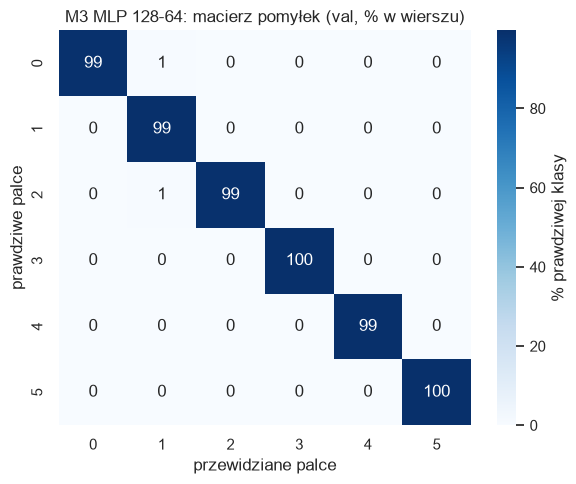

In [7]:
cm = confusion_matrix(y_va, best_pred, normalize="true")
plt.figure(figsize=(6, 5))
sns.heatmap(cm * 100, annot=True, fmt=".0f", cmap="Blues", cbar_kws={"label": "% prawdziwej klasy"})
plt.xlabel("przewidziane palce"); plt.ylabel("prawdziwe palce")
plt.title(f"{best_name}: macierz pomyłek (val, % w wierszu)")
plt.tight_layout(); plt.savefig(FIG / "explore_A_confusion.png", dpi=150); plt.show()

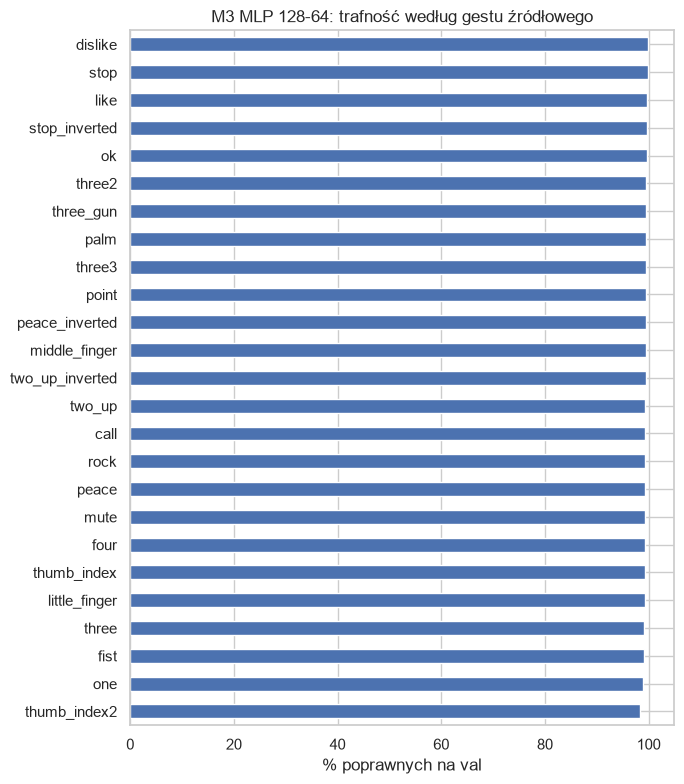

,trafność,najczęstszy błąd,z mapowania
gest,,,
thumb_index2,0.982979,1,2
one,0.989865,2,1
fist,0.991447,1,0
three,0.991933,2,3
little_finger,0.992209,0,1
thumb_index,0.992635,1,2
four,0.992981,5,4
mute,0.993239,2,1


In [8]:
val_pred = pd.DataFrame({"gesture": d_va.label.values, "y": y_va, "pred": best_pred})
per_gesture = (val_pred.assign(ok=val_pred.pred == val_pred.y).groupby("gesture")[["ok"]].mean()
               .rename(columns={"ok": "trafność"}))
wrong = val_pred[val_pred.pred != val_pred.y]
per_gesture["najczęstszy błąd"] = wrong.groupby("gesture").pred.agg(lambda p: p.mode()[0])
per_gesture["z mapowania"] = per_gesture.index.map(GESTURE_TO_COUNT)
per_gesture = per_gesture.sort_values("trafność")
ax = per_gesture["trafność"].mul(100).plot.barh(figsize=(7, 8))
ax.set(xlabel="% poprawnych na val", ylabel="", title=f"{best_name}: trafność według gestu źródłowego")
plt.tight_layout(); plt.savefig(FIG / "explore_A_per_gesture.png", dpi=150); plt.show()
per_gesture.rename_axis("gest").head(8)

## GreenAI w namacalnych jednostkach

Do porównania zakładamy, że przeciętny samochód benzynowy emituje około 120 g CO2 na km.

In [9]:
CAR_G_PER_KM = 120
green = summary.drop("R0 reguła")[["train_time_s", "energy_kwh", "co2_g"]].copy()
green["car_metres"] = green.co2_g / CAR_G_PER_KM * 1000
green["phone_charges"] = green.energy_kwh / 0.015  # ~15 Wh na pełne ładowanie smartfona
green.round({"train_time_s": 1, "energy_kwh": 5, "co2_g": 2, "car_metres": 1, "phone_charges": 3}).rename(
    columns={"car_metres": "metry samochodem", "phone_charges": "ładowania telefonu"})

,train_time_s,energy_kwh,co2_g,metry samochodem,ładowania telefonu
model,,,,,
M1 regresja logistyczna,44.9,0.00036,0.24,2.0,0.024
M2 drzewa gradient boosting,26.4,0.00048,0.32,2.6,0.032
M3 MLP 128-64,27.0,0.00026,0.17,1.4,0.017


## Wnioski

- **Reguła (R0) to słaby punkt odniesienia.** Macro F1 0.67. Ręcznie napisana geometria zawodzi na kciuku i na
  palcach skierowanych w kamerę.
- **Model liniowy nie wystarcza.** Regresja logistyczna osiąga około 0.85 macro F1.
- **Modele nieliniowe prawie rozwiązują zadanie na val.** Drzewa gradient boosting mają około 0.99, MLP też około 0.99.
  Trening trwa poniżej minuty na CPU laptopa i kosztuje ułamek grama CO2 (kilka metrów jazdy samochodem).
- **MLP to najlepszy kandydat na telefon.** Ma najwyższe macro F1, około 175 KB, poniżej 0.2 ms na dłoń na laptopie
  i łatwy eksport (TFLite/ONNX). Drzewa są 6x większe i wolne dla pojedynczej próbki w sklearn.
- **Pozostałe błędy dotyczą kciuka.** `thumb_index2` i `thumb_index` spadają do 1, `one` do 2, `fist` do 1.

**Dlaczego jeszcze nie ufamy wynikowi 0.99.** HaGRID ma 25 stałych póz dla naszych 6 liczb palców. Tak dokładny
model nauczył się rozpoznawać te pozy, a niekoniecznie liczyć palce. Osoba w aplikacji może pokazać "3" jako
serdeczny + mały + środkowy, a takiej kombinacji nie ma w danych. Prawdziwym testem są więc nasze własne nagrania
z kamery z dowolnymi kombinacjami palców. Kurs i tak ich wymaga (weryfikacja filmem). Ścieżka B (wycinki obrazów)
ma to samo ryzyko, bo uczy się z tych samych etykiet.

**Konsekwencje dla procesu:**
- Ścieżka A działa i jest tania. Jej przetwarzanie wstępne i augmentacja działają na landmarkach (normalizacja,
  odbicie lustrzane, obrót, szum). Do xAI pasuje SHAP na stawach, a nie Grad-CAM.
- Diagram kursu mówi o przetwarzaniu wstępnym i augmentacji *obrazów*. Czy potok na punktach charakterystycznych
  to spełnia, trzeba zapytać na konsultacjach. Możliwe jest rozwiązanie hybrydowe. MediaPipe znajduje dłoń, a mała
  sieć CNN klasyfikuje wycinek.
- Ścieżka B nadal potrzebuje obrazów. Serwer z obrazami jest zablokowany w obecnej sieci, więc podzbiór trzeba
  pobrać gdzie indziej.